### Dataset Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!cp "/content/drive/MyDrive/ معكسر علم البيانات والذكاء الاصطماعي/sds_swimmer.zip" /content/
!unzip -q /content/sds_swimmer.zip -d /content/

print("Data ready")

Mounted at /content/drive
Data ready


Using: /content/sds_swimmer/data.yaml
Classes: ['swimmer']
Training images found: 5000
Images with swimmers: 234


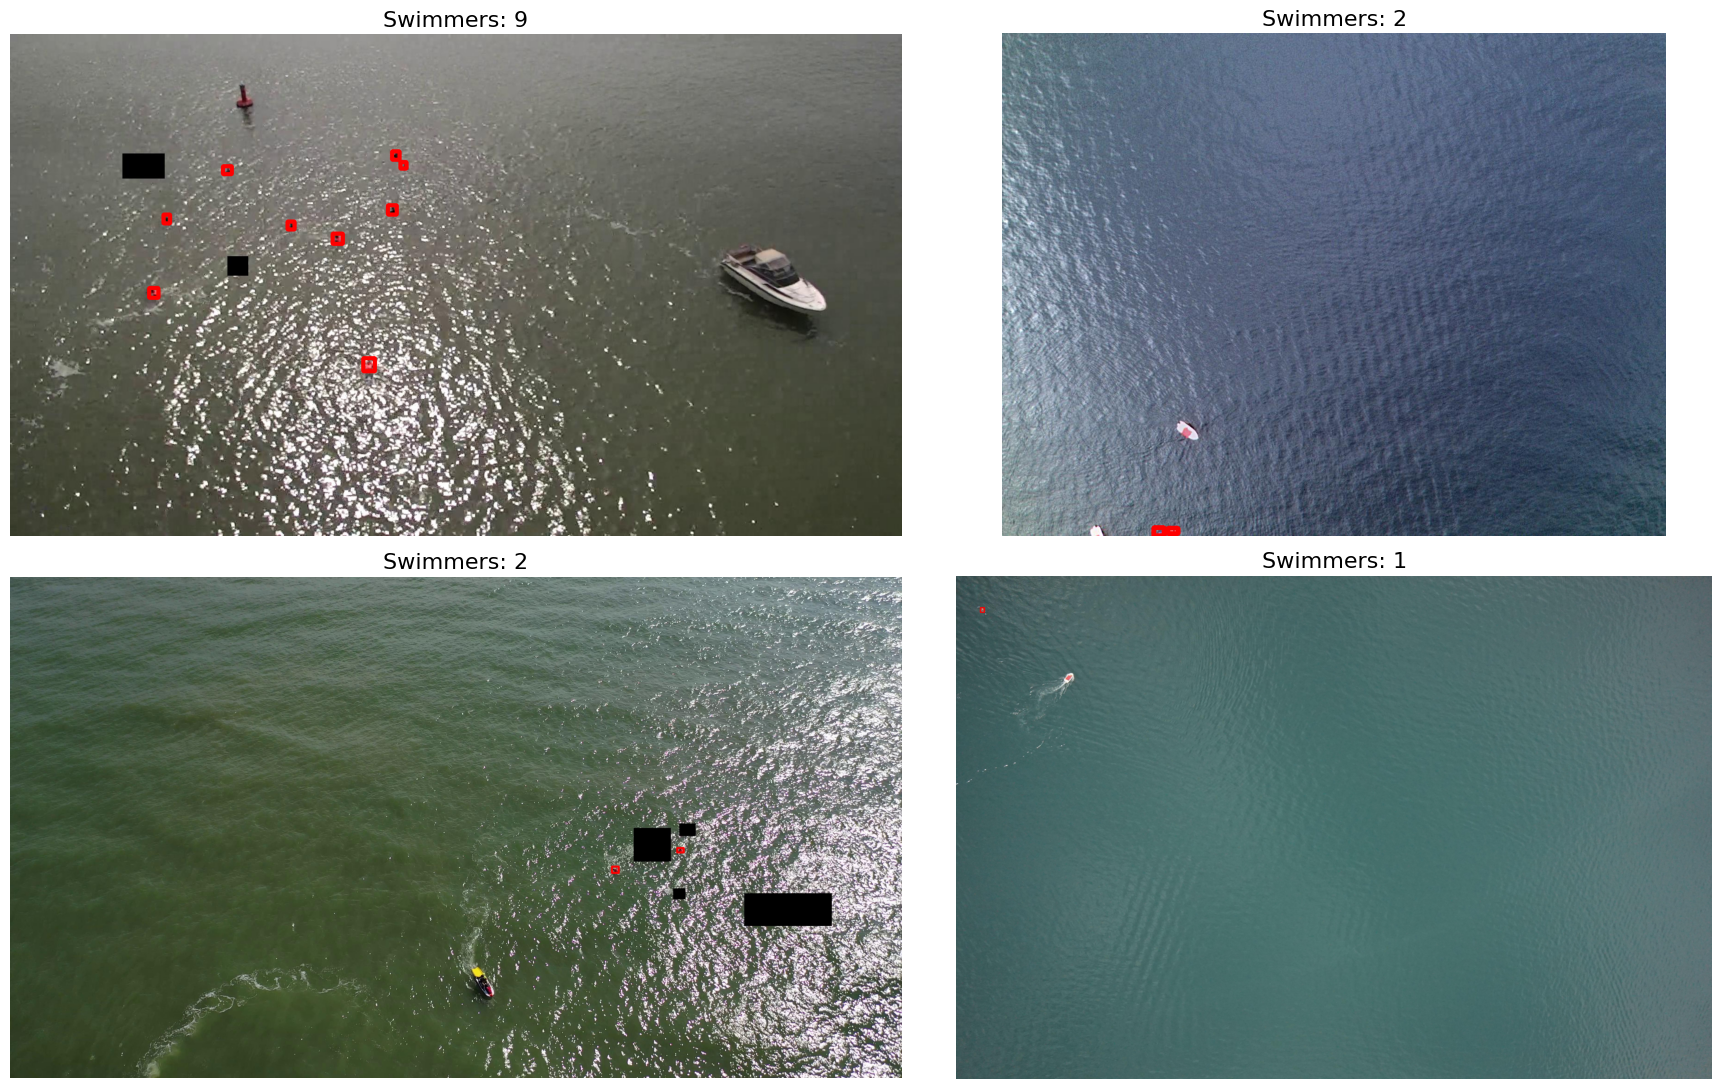

In [ ]:
import glob, random, yaml, cv2, os
import matplotlib.pyplot as plt

yaml_files = glob.glob('/content/**/data.yaml', recursive=True)

if not yaml_files:
    raise FileNotFoundError("data.yaml was not found. Check that the ZIP was extracted correctly.")

yml = yaml_files[0]
print("Using:", yml)

# Load class names
names = yaml.safe_load(open(yml))['names']
names = names if isinstance(names, list) else [names[k] for k in sorted(names)]

print("Classes:", names)
SWIMMER = names.index('swimmer')

# Find training images based on the dataset structure
imgs = [
    p for p in glob.glob('/content/**/train/**/*.*', recursive=True)
    if p.lower().endswith(('.jpg', '.jpeg', '.png'))
    and '/images/' in p
]

print("Training images found:", len(imgs))

# Read swimmer labels
def swimmers_in(p):
    lbl = p.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'

    if not os.path.exists(lbl):
        return []

    return [
        list(map(float, line.split()[1:5]))
        for line in open(lbl)
        if line.strip() and int(line.split()[0]) == SWIMMER
    ]

# Find images containing swimmers
sample_size = min(300, len(imgs))

with_swimmers = [
    p for p in random.sample(imgs, sample_size)
    if swimmers_in(p)
]

print("Images with swimmers:", len(with_swimmers))

# Display 4 random examples
if len(with_swimmers) < 4:
    raise ValueError("Less than 4 images with swimmer annotations were found.")

fig, axes = plt.subplots(2, 2, figsize=(18, 11))

for ax, p in zip(axes.flat, random.sample(with_swimmers, 4)):

    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    boxes = swimmers_in(p)

    for x, y, bw, bh in boxes:
        x1 = int((x - bw / 2) * w)
        y1 = int((y - bh / 2) * h)
        x2 = int((x + bw / 2) * w)
        y2 = int((y + bh / 2) * h)

        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 8)

    ax.imshow(img)
    ax.set_title(f'Swimmers: {len(boxes)}', fontsize=16)
    ax.axis('off')

plt.tight_layout()
plt.show()

# YOLO26s — Baseline Training (Swimmer Detection)

| Setting | Value |
|---|---|
| Epochs | 30 |
| Image size | 640 |
| Batch size | 8 |
| Optimizer | AdamW |
| Learning rate (lr0) | 0.001 |
| Patience | 10 |
| Seed | 42 |



In [ ]:
ULTRALYTICS_VERSION = "8.4.216"
!pip install -q ultralytics=={ULTRALYTICS_VERSION}

import ultralytics, torch
ultralytics.checks()
print("Ultralytics:", ultralytics.__version__)
print("Torch:", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 13.9/112.6 GB disk)
Ultralytics: 8.4.216
Torch: 2.14.1+cu130 | CUDA: True | Tesla T4


## 2. Verifying the dataset splits and writing a clean `data.yaml`


In [ ]:
import os, glob, yaml

DATA_ROOT = os.path.dirname(yml)
cfg = yaml.safe_load(open(yml))

def find_split_dir(split):
    """Return the absolute image folder for a split (handles train/images or images/train layouts)."""
    rel = cfg.get(split)
    if isinstance(rel, str):
        base = cfg.get('path') or DATA_ROOT
        base = base if os.path.isabs(base) else os.path.join(DATA_ROOT, base)
        for cand in [rel, os.path.join(base, rel), os.path.join(DATA_ROOT, rel)]:
            if os.path.isdir(cand):
                return os.path.abspath(cand)
    for pattern in [f'{DATA_ROOT}/**/{split}/images', f'{DATA_ROOT}/**/images/{split}']:
        hits = glob.glob(pattern, recursive=True)
        if hits:
            return os.path.abspath(hits[0])
    return None

splits = {s: find_split_dir(s) for s in ['train', 'val', 'test']}
if splits['val'] is None:
    splits['val'] = find_split_dir('valid')
print(splits)
assert all(splits.values()), "A split folder is missing — check the ZIP structure."

def split_stats(img_dir):
    imgs = [p for p in glob.glob(f'{img_dir}/*') if p.lower().endswith(('.jpg', '.jpeg', '.png'))]
    n_boxes, n_empty = 0, 0
    for p in imgs:
        lbl = p.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
        lines = [l for l in open(lbl)] if os.path.exists(lbl) else []
        lines = [l for l in lines if l.strip()]
        n_boxes += len(lines)
        n_empty += (len(lines) == 0)
    return len(imgs), n_boxes, n_empty

print(f"{'split':<6}{'images':>8}{'swimmers':>10}{'no-swimmer imgs':>17}")
for s, d in splits.items():
    n, b, e = split_stats(d)
    print(f"{s:<6}{n:>8}{b:>10}{e:>17}")

DATA_YAML = '/content/swimmer_data.yaml'
yaml.safe_dump({'path': '/', 'train': splits['train'], 'val': splits['val'],
                'test': splits['test'], 'names': {0: 'swimmer'}},
               open(DATA_YAML, 'w'), sort_keys=False)
print(open(DATA_YAML).read())

{'train': '/content/sds_swimmer/train/images', 'val': '/content/sds_swimmer/val/images', 'test': '/content/sds_swimmer/test/images'}
split   images  swimmers  no-swimmer imgs
train     5000     20992             1102
val       1000      4068              160
test      1000      4193              225
path: /
train: /content/sds_swimmer/train/images
val: /content/sds_swimmer/val/images
test: /content/sds_swimmer/test/images
names:
  0: swimmer



## 3. Training configuration


In [ ]:
DRIVE_DIR = "/content/drive/MyDrive/ معكسر علم البيانات والذكاء الاصطماعي"
PROJECT_DIR = f"{DRIVE_DIR}/runs_cv"
os.makedirs(PROJECT_DIR, exist_ok=True)

BASE_CFG = dict(
    epochs=30,
    imgsz=640,
    batch=8,
    optimizer='AdamW',
    lr0=0.001,
    patience=10,
    seed=42,
    deterministic=True,
    workers=2,
    plots=True,
)

MODEL_NAME = 'yolo26s'
RUN_NAME   = f'{MODEL_NAME}_baseline'
print(BASE_CFG)

{'epochs': 30, 'imgsz': 640, 'batch': 8, 'optimizer': 'AdamW', 'lr0': 0.001, 'patience': 10, 'seed': 42, 'deterministic': True, 'workers': 2, 'plots': True}


## 4. Train YOLO26s (baseline)


In [ ]:
from ultralytics import YOLO

model = YOLO(f'{MODEL_NAME}.pt')

results = model.train(
    data=DATA_YAML,
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=True,
    **BASE_CFG,
)

RUN_DIR = str(results.save_dir)
BEST_W  = f'{RUN_DIR}/weights/best.pt'
print("Run dir:", RUN_DIR)
print("Best weights:", BEST_W)

New https://pypi.org/project/ultralytics/8.4.218 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/swimmer_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.

## 5. Training curves

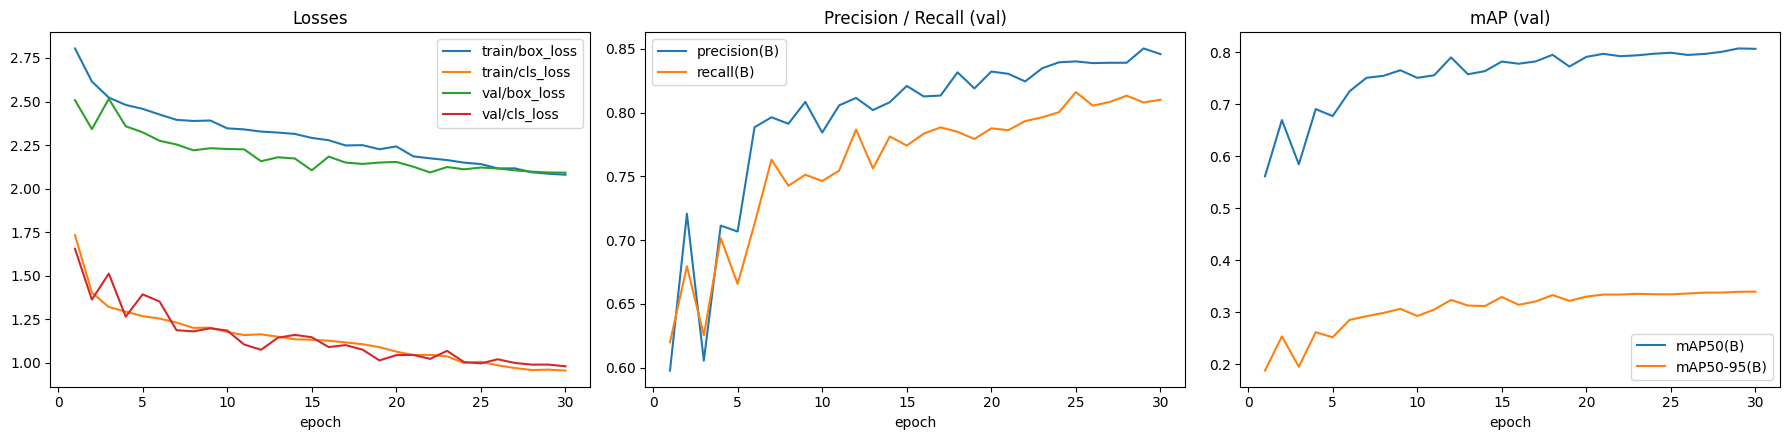

Epochs run: 30 | best epoch: 30 | best val mAP50-95: 0.3399


In [ ]:
import pandas as pd

RUN_DIR = f'{PROJECT_DIR}/{RUN_NAME}'
BEST_W  = f'{RUN_DIR}/weights/best.pt'

hist = pd.read_csv(f'{RUN_DIR}/results.csv')
hist.columns = hist.columns.str.strip()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for col in ['train/box_loss', 'train/cls_loss', 'val/box_loss', 'val/cls_loss']:
    if col in hist:
        axes[0].plot(hist['epoch'], hist[col], label=col)
axes[0].set_title('Losses'); axes[0].set_xlabel('epoch'); axes[0].legend()

for col in ['metrics/precision(B)', 'metrics/recall(B)']:
    axes[1].plot(hist['epoch'], hist[col], label=col.split('/')[1])
axes[1].set_title('Precision / Recall (val)'); axes[1].set_xlabel('epoch'); axes[1].legend()

for col in ['metrics/mAP50(B)', 'metrics/mAP50-95(B)']:
    axes[2].plot(hist['epoch'], hist[col], label=col.split('/')[1])
axes[2].set_title('mAP (val)'); axes[2].set_xlabel('epoch'); axes[2].legend()

plt.tight_layout(); plt.show()

best_epoch = hist['metrics/mAP50-95(B)'].idxmax()
print(f"Epochs run: {len(hist)} | best epoch: {int(hist.loc[best_epoch, 'epoch'])} "
      f"| best val mAP50-95: {hist.loc[best_epoch, 'metrics/mAP50-95(B)']:.4f}")

## 6. Evaluate best weights on Val and Test

In [ ]:
best_model = YOLO(BEST_W)

def evaluate(split):
    m = best_model.val(data=DATA_YAML, split=split, imgsz=BASE_CFG['imgsz'], batch=BASE_CFG['batch'],
                       project=PROJECT_DIR, name=f'{RUN_NAME}_eval_{split}', exist_ok=True, plots=True)
    p, r = m.box.mp, m.box.mr
    return {
        'model': MODEL_NAME, 'split': split,
        'precision': p, 'recall': r,
        'f1': 2 * p * r / (p + r + 1e-9),
        'mAP50': m.box.map50, 'mAP50-95': m.box.map,
        'inference_ms_per_img': m.speed['inference'],
    }

metrics = pd.DataFrame([evaluate('val'), evaluate('test')])
metrics.round(4)

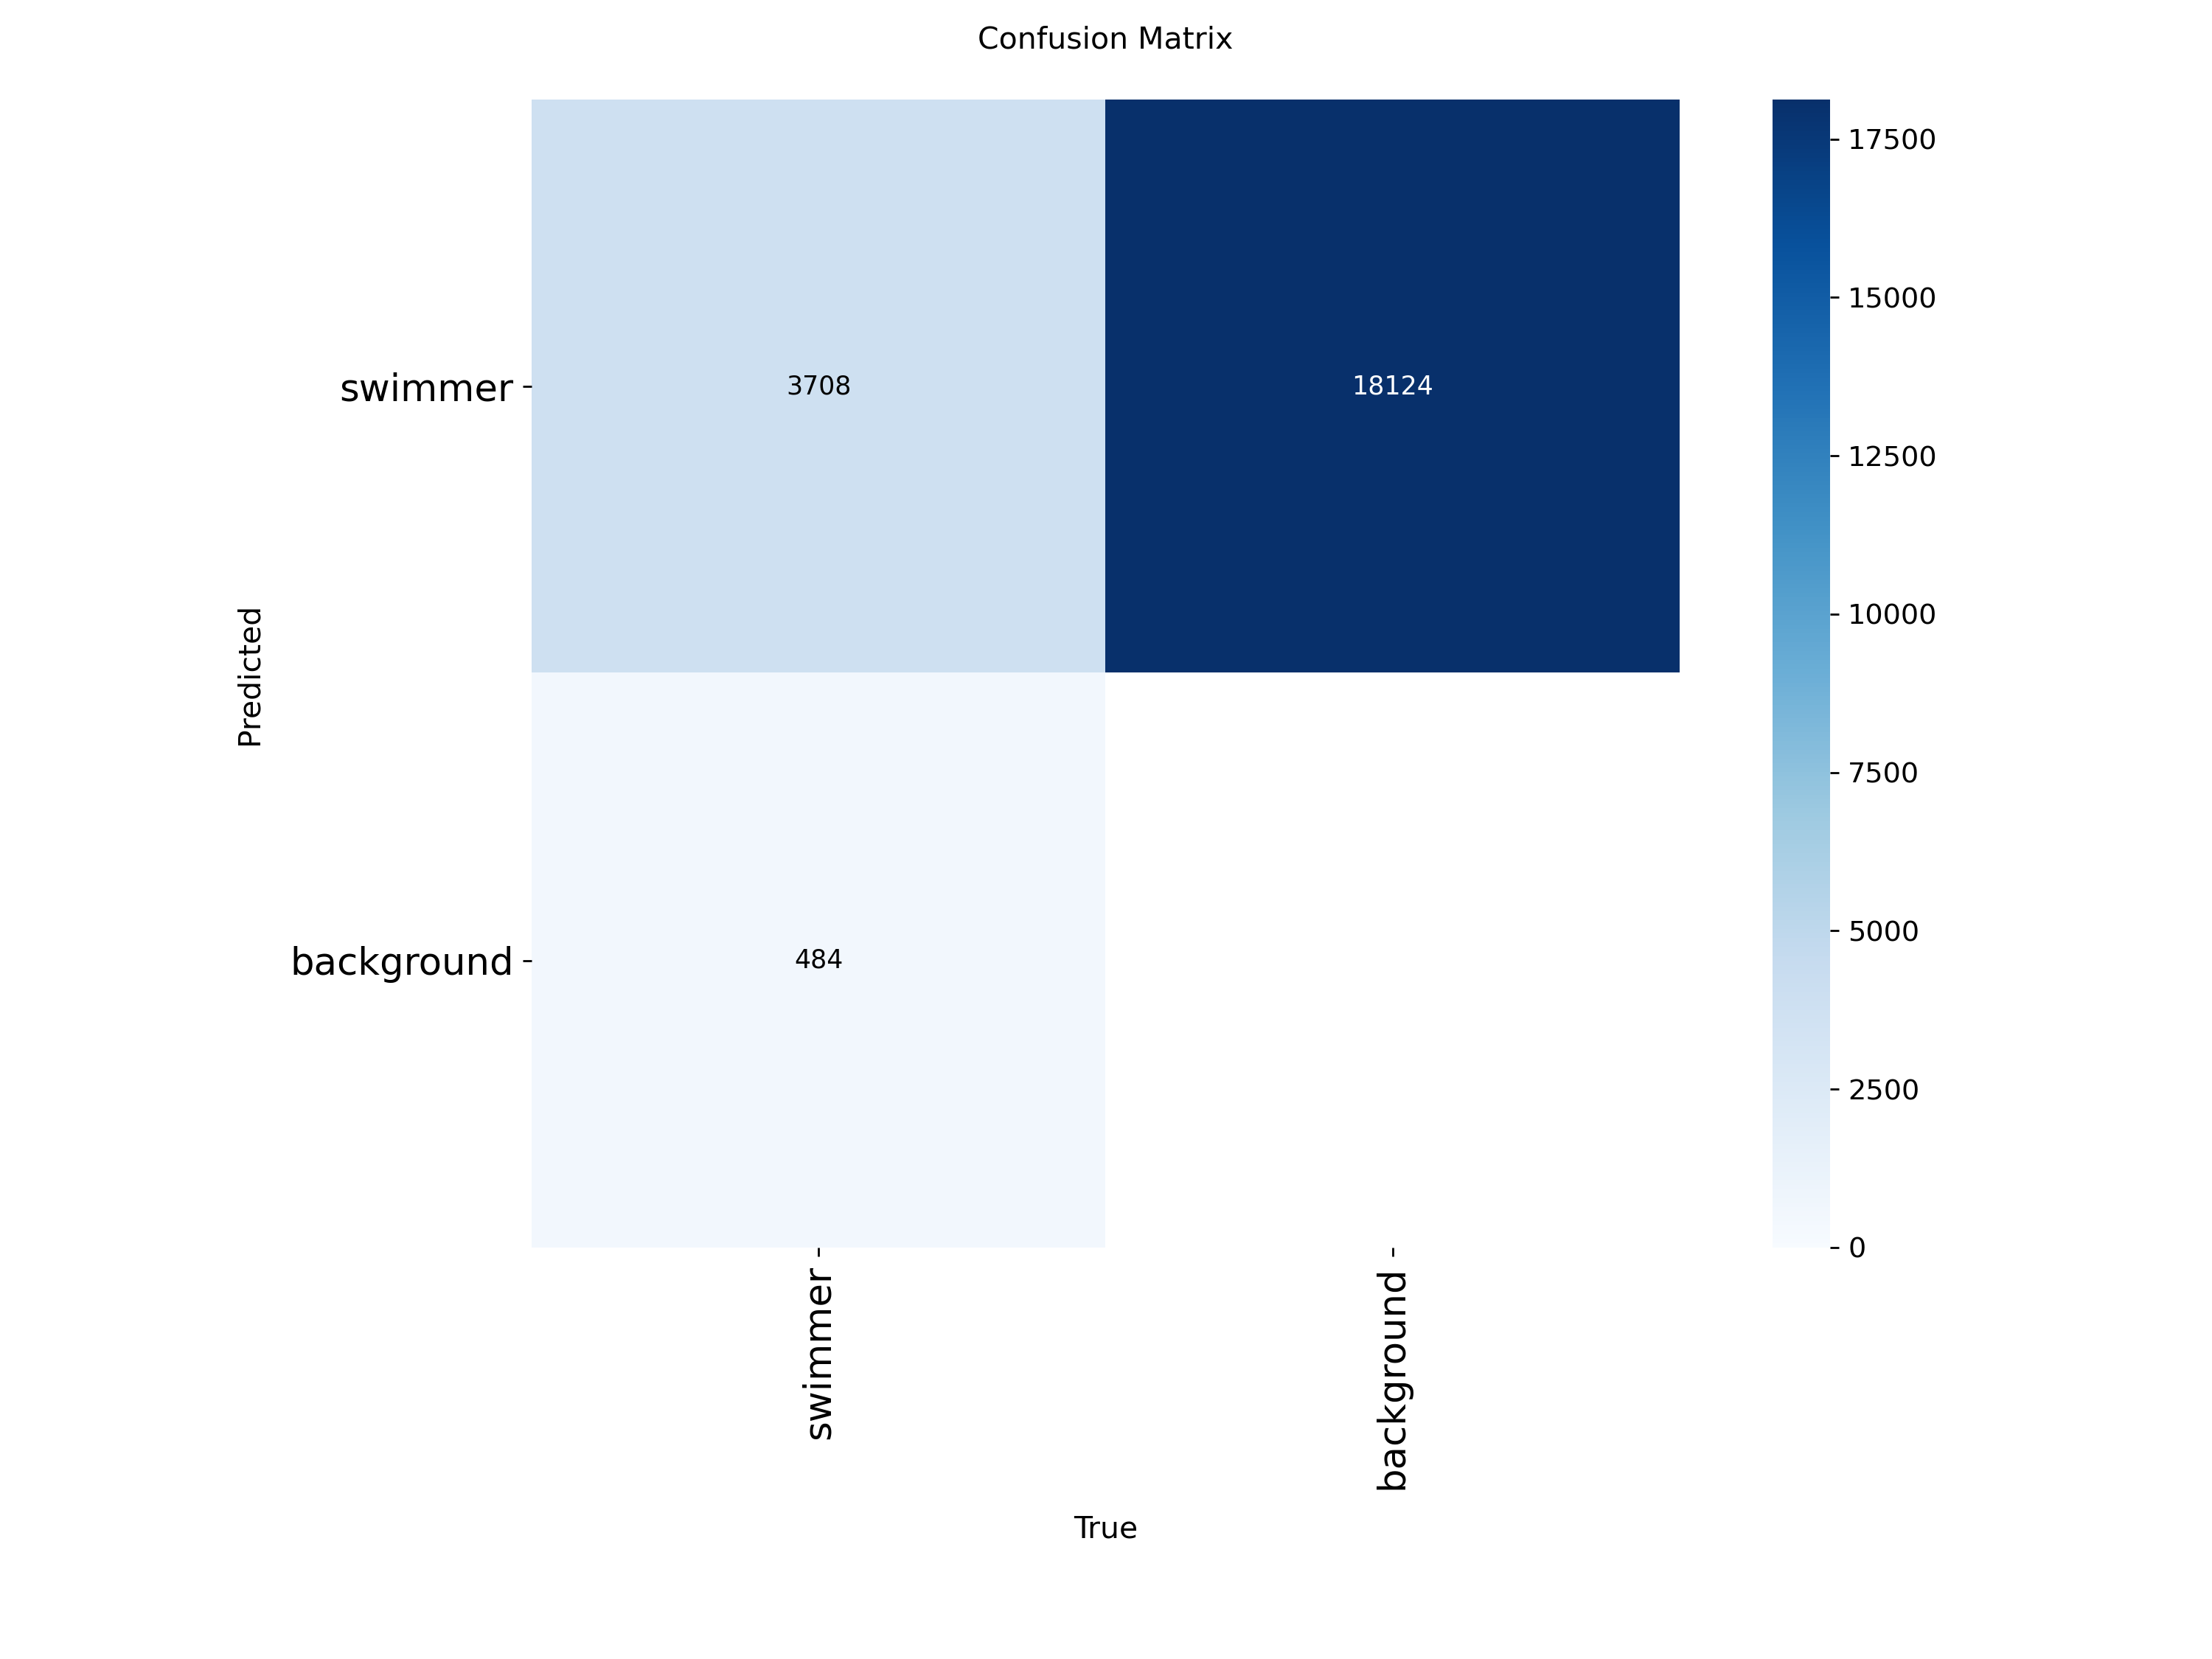

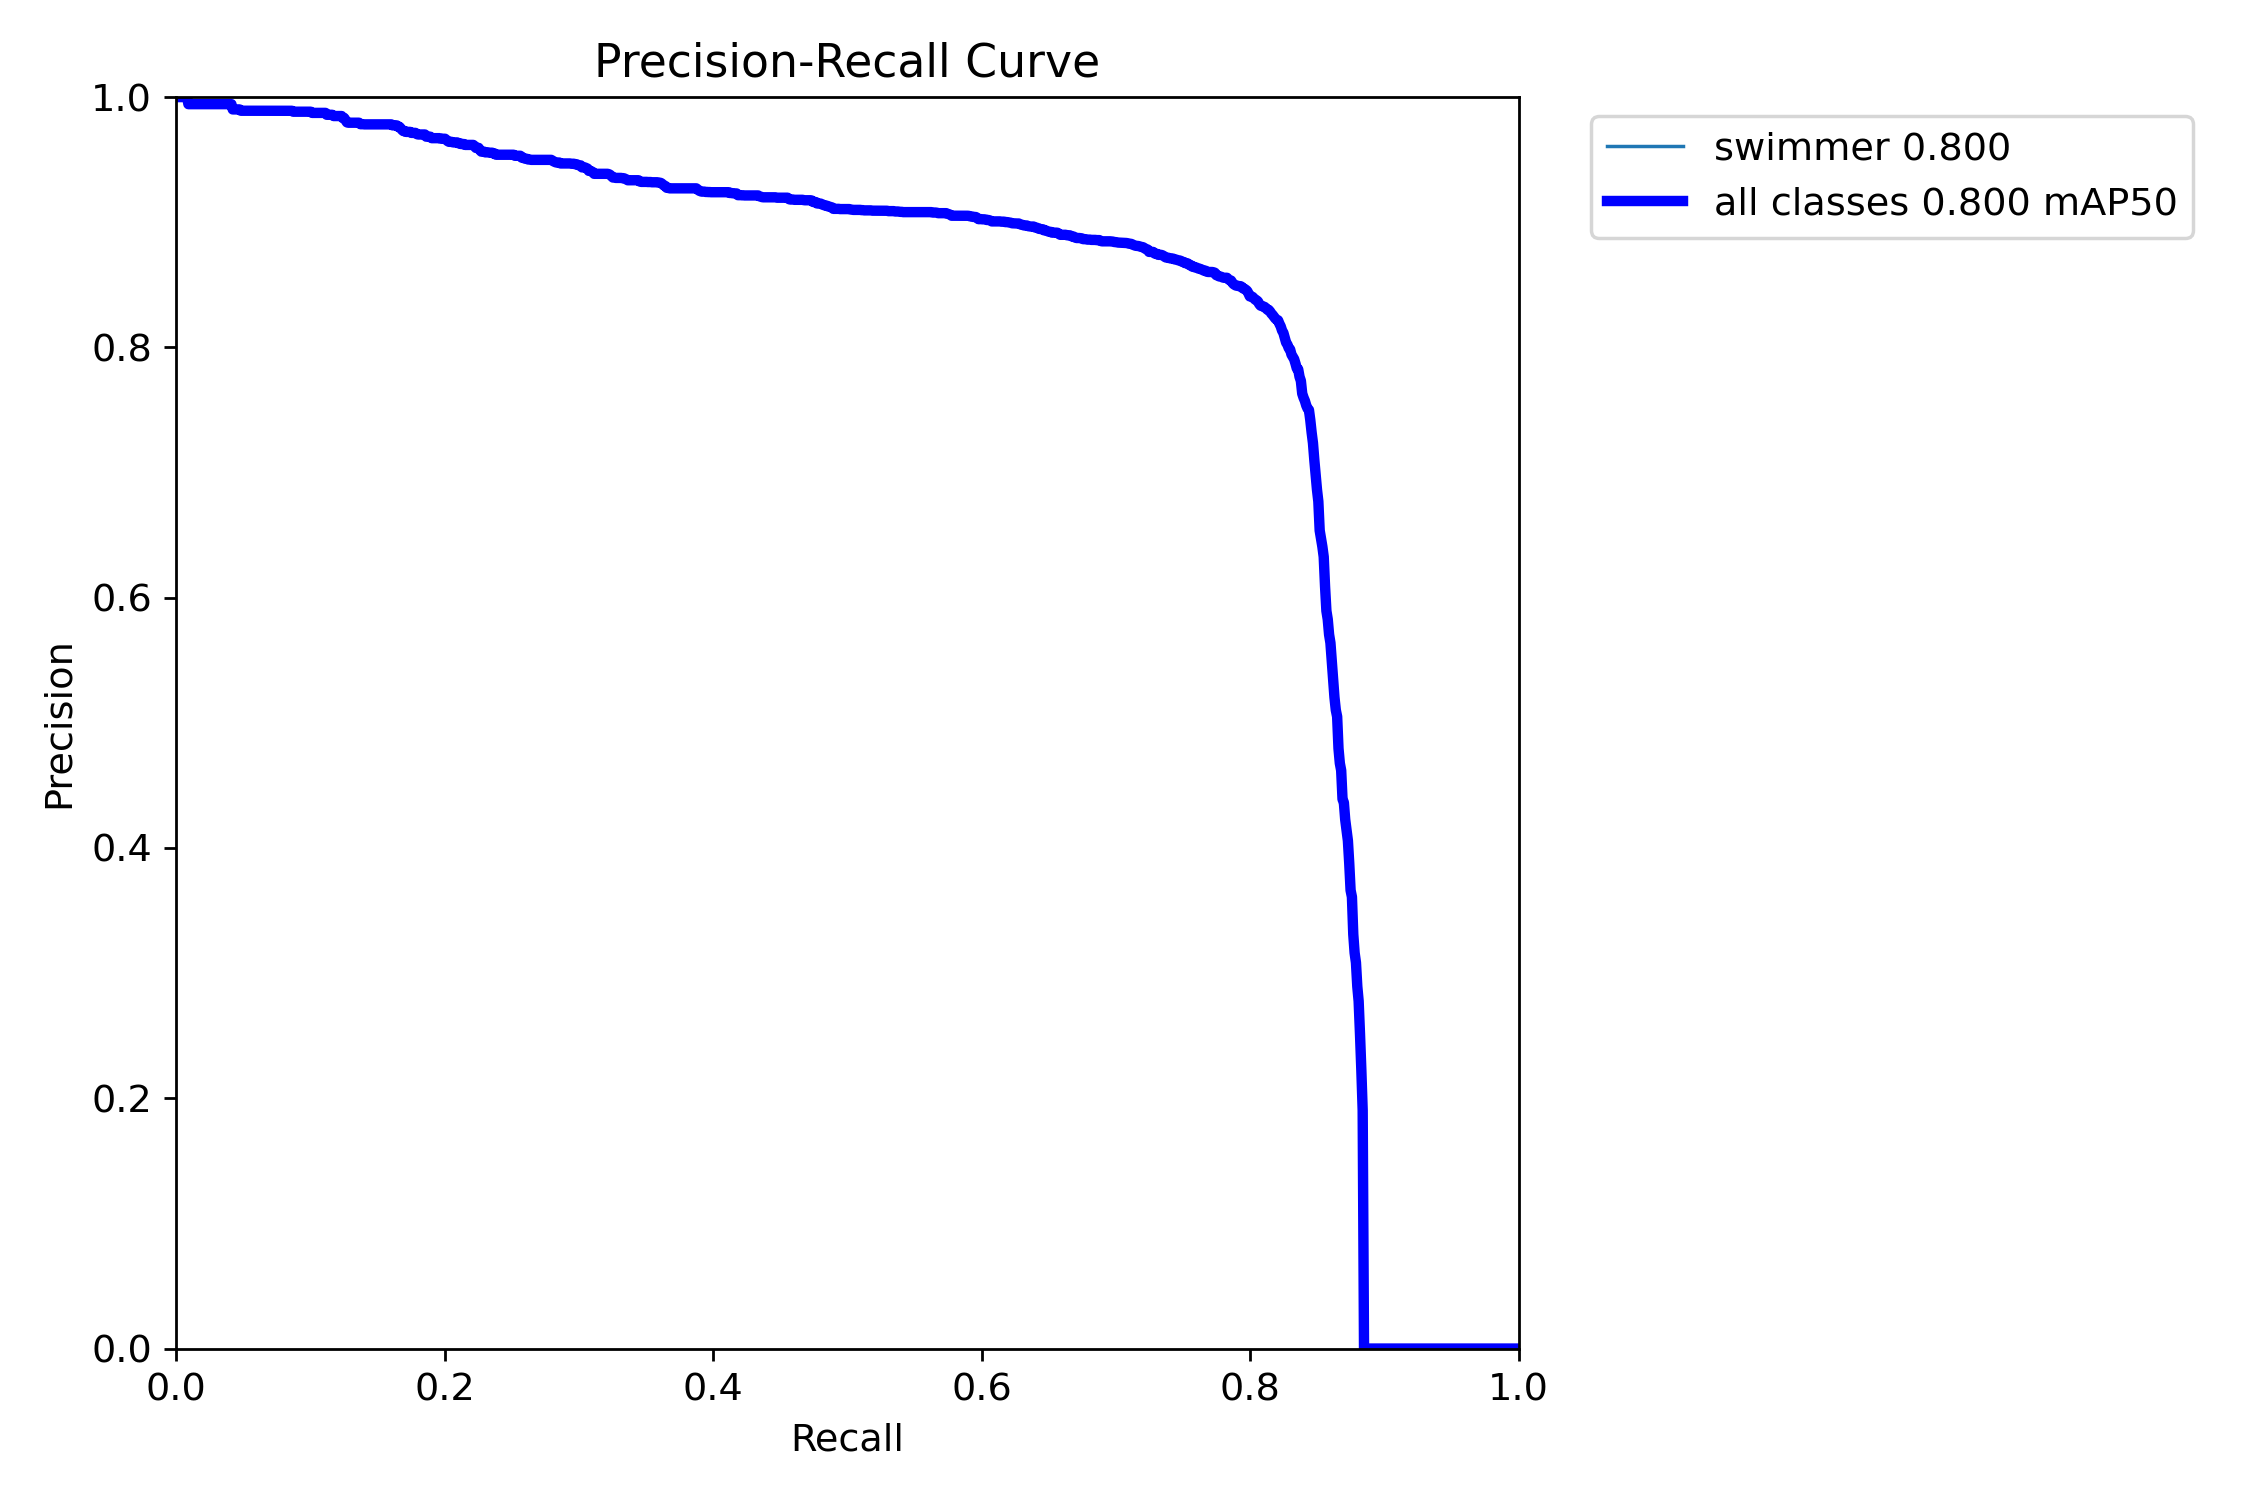

In [ ]:
from IPython.display import Image, display
cm = f'{PROJECT_DIR}/{RUN_NAME}_eval_test/confusion_matrix.png'
pr = f'{PROJECT_DIR}/{RUN_NAME}_eval_test/BoxPR_curve.png'
for f in [cm, pr]:
    if os.path.exists(f):
        display(Image(filename=f, width=650))